In [76]:
import numpy as np
import random
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

In [77]:
X_train = np.loadtxt('./input.csv', delimiter = ',')
Y_train = np.loadtxt('./labels.csv', delimiter = ',')

X_test = np.loadtxt('./input_test.csv', delimiter = ',')
Y_test = np.loadtxt('./labels_test.csv', delimiter = ',')

In [78]:
X_train = X_train.reshape(len(X_train), 100, 100, 3)
Y_train = Y_train.reshape(len(Y_train), 1)
X_test = X_test.reshape(len(X_test), 100, 100, 3)
Y_test = Y_test.reshape(len(Y_test), 1)

X_train = X_train / 255.0
X_test = X_test / 255.0

In [79]:
print("Shape of X_train: ", X_train.shape) 
print("Shape of X_test: ", X_test.shape)
print("Shape of Y_train: ", Y_train.shape)
print("Shape of Y_train: ", Y_train.shape)

Shape of X_train:  (2000, 100, 100, 3)
Shape of X_test:  (400, 100, 100, 3)
Shape of Y_train:  (2000, 1)
Shape of Y_train:  (2000, 1)


In [80]:
X_train[1:]

array([[[[0.51372549, 0.50196078, 0.52941176],
         [0.62745098, 0.61568627, 0.64313725],
         [0.77647059, 0.75294118, 0.8       ],
         ...,
         [0.98039216, 0.97647059, 0.96862745],
         [1.        , 1.        , 0.99215686],
         [0.98039216, 0.97647059, 0.96078431]],

        [[0.54901961, 0.5372549 , 0.56470588],
         [0.49803922, 0.48627451, 0.51372549],
         [0.47058824, 0.44705882, 0.48627451],
         ...,
         [0.98431373, 0.99215686, 0.98823529],
         [0.99607843, 1.        , 0.99215686],
         [0.99607843, 1.        , 0.98431373]],

        [[0.8       , 0.79215686, 0.81176471],
         [0.73333333, 0.7254902 , 0.74509804],
         [0.57647059, 0.55686275, 0.58039216],
         ...,
         [0.97647059, 1.        , 1.        ],
         [0.93333333, 0.96862745, 0.94901961],
         [0.90980392, 0.94509804, 0.9254902 ]],

        ...,

        [[0.68235294, 0.71372549, 0.76470588],
         [0.6745098 , 0.70588235, 0.75686275]

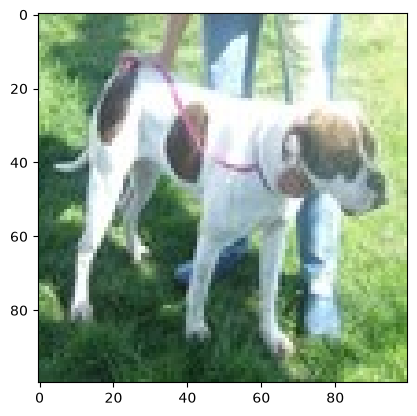

In [81]:
idx = random.randint(0, len(X_train))
plt.imshow(X_train[idx, :])

Mode

In [82]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(100, 100, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

c:\Users\lenov\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [83]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [84]:
model.fit(X_train, Y_train, epochs=10, batch_size=32)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.5115 - loss: 0.7573
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.5685 - loss: 0.6740
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - accuracy: 0.6570 - loss: 0.6148
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - accuracy: 0.7315 - loss: 0.5412
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.7925 - loss: 0.4530
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.8210 - loss: 0.3920
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.8540 - loss: 0.3389
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.9135 - loss: 0.2302
Epoch 9/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.9345 - loss: 0.1708
Epoch 10/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.9405 - loss: 0.1609


In [85]:
model.evaluate(X_test, Y_test)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6225 - loss: 1.2359


[1.2358884811401367, 0.6225000023841858]

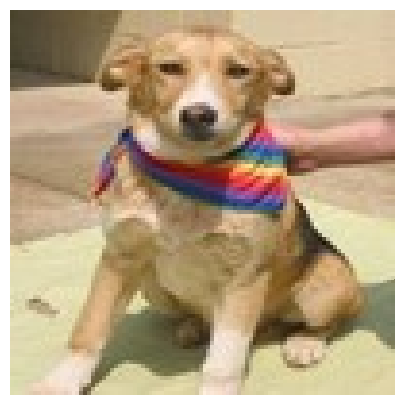

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step
Predicted image: dog


In [89]:
# Select a random test image
idx2 = random.randint(0, len(X_test)-1)

# Display image
plt.figure(figsize=(5,5))
plt.imshow(X_test[idx2])
plt.axis('off')
plt.show()

# Predict
y_pred = model.predict(X_test[idx2].reshape(1, 100, 100, 3))

if y_pred[0][0] > 0.5:
    pred = 'cat'
else:
    pred = 'dog'

print("Predicted image:", pred)